In [10]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import sys
sys.path.append("..")
import matplotlib.pyplot as plt

from src.config import cfg

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


2026-11-24 11:41:09,455 | INFO | src.data_loader | data loaded
2026-11-24 11:41:09,492 | INFO | src.cleaning | Dropped rows with invalid dates or missing target
2026-11-24 11:41:09,514 | INFO | src.cleaning | Dropped exact duplicate rows
2026-11-24 11:41:09,521 | INFO | src.cleaning | Sorted data chronologically
2026-11-24 11:41:09,540 | INFO | src.cleaning | Reindexed to complete hourly range
2026-11-24 11:41:09,545 | INFO | src.cleaning | Interpolated missing target values
2026-11-24 11:41:09,546 | INFO | src.cleaning | Cleaning completed | Rows: 145392 | Datetime type: datetime64[us] | Target type: float64


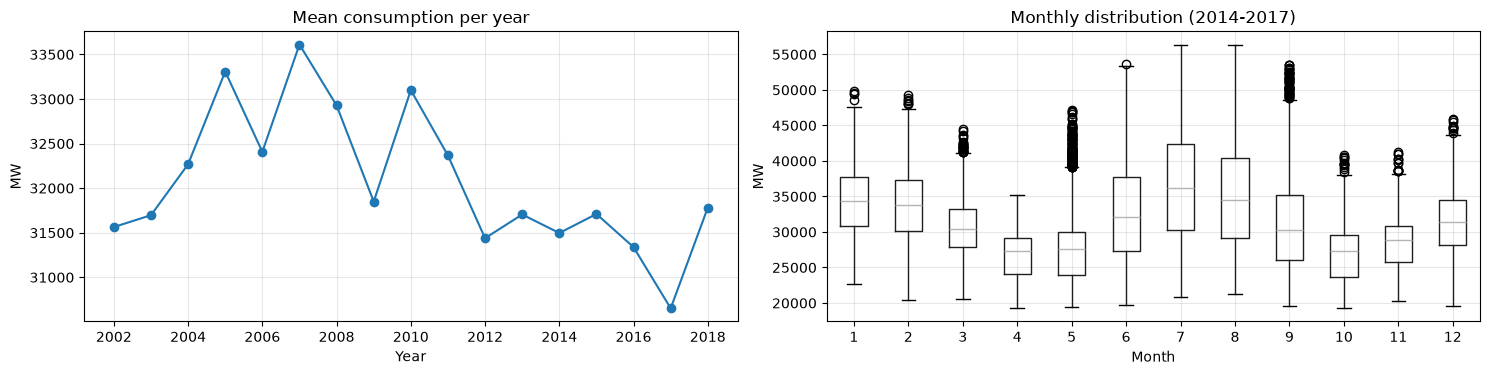

In [21]:

from src.model import plot_time_series, plot_seasonality
from src.data_loader import load_raw
from src.cleaning import clean

clean_df = clean(load_raw())

path_consumption_timeline = plot_time_series(clean_df, cfg.FIGURES_DIR)
path_seasonality =plot_seasonality(clean_df, cfg.FIGURES_DIR)

# Annual trend and yearly box plots to reveal level shifts / seasonality changes.
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
yearly = clean_df.groupby(clean_df["Datetime"].dt.year)[cfg.TARGET_COL].mean()
axes[0].plot(yearly.index, yearly.values, marker="o", color="#1f77b4")
axes[0].set(title="Mean consumption per year", xlabel="Year", ylabel="MW")

sample = clean_df[clean_df["Datetime"].dt.year.between(2014, 2017)].copy()
sample["Month"] = sample["Datetime"].dt.month
sample.boxplot(column=cfg.TARGET_COL, by="Month", ax=axes[1])
axes[1].set(title="Monthly distribution (2014-2017)", xlabel="Month", ylabel="MW")
axes[1].get_figure().suptitle("")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


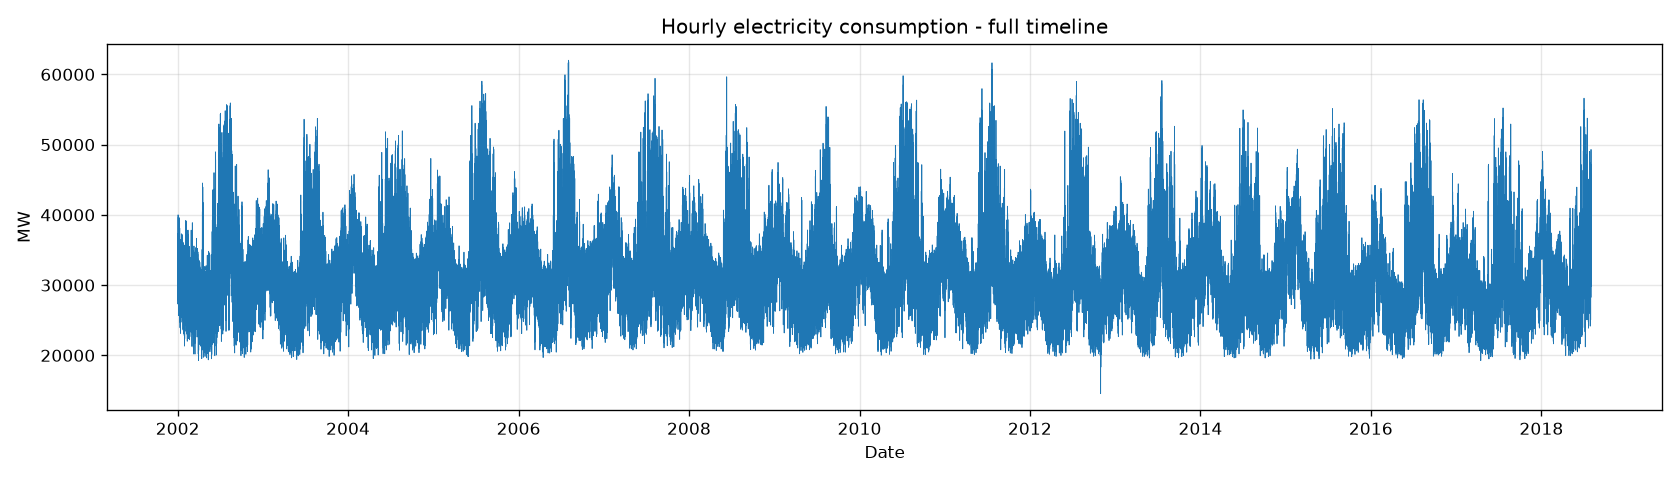

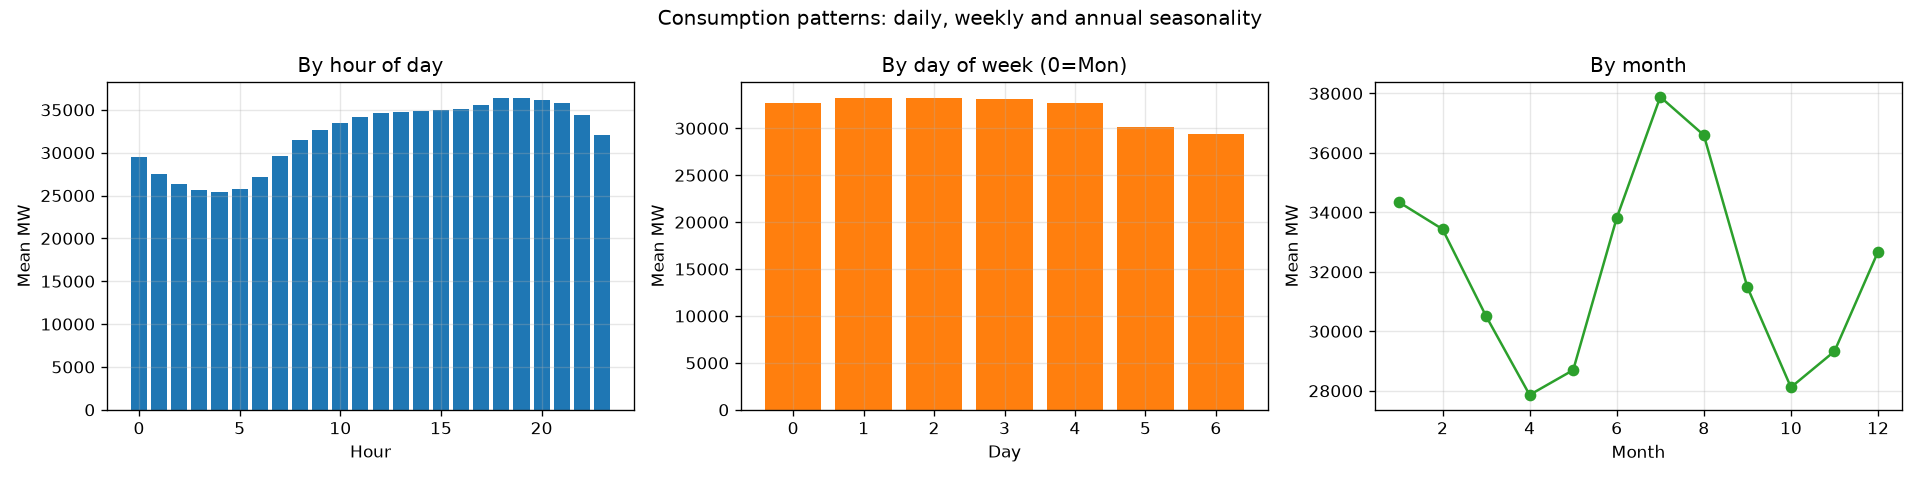

In [22]:
from IPython.display import Image, display

print

display(Image(filename=str(path_consumption_timeline)))
display(Image(filename=str(path_seasonality)))